In [ ]:
!pip install pandas scikit-learn matplotlib seaborn

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import joblib
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

In [ ]:
def load_data():
    print("[INFO] Loading datasets...")
    train_df = pd.read_csv("train.csv", header=None, names=["Class", "Title", "Description"])
    test_df = pd.read_csv("test.csv", header=None, names=["Class", "Title", "Description"])
    train_df = train_df[pd.to_numeric(train_df["Class"], errors="coerce").notnull()]
    test_df = test_df[pd.to_numeric(test_df["Class"], errors="coerce").notnull()]
    train_df["Class"] = train_df["Class"].astype(int)
    test_df["Class"] = test_df["Class"].astype(int)
    train_df["Text"] = train_df["Title"].fillna("") + " " + train_df["Description"].fillna("")
    test_df["Text"] = test_df["Title"].fillna("") + " " + test_df["Description"].fillna("")
    X_train, y_train = train_df["Text"], train_df["Class"]
    X_test, y_test = test_df["Text"], test_df["Class"]
    return X_train, y_train, X_test, y_test

In [ ]:
def evaluation_model(model_name,y_true,y_pred):
  acc = accuracy_score(y_true,y_pred)
  print(f"Accuracy: {acc * 100:.2f}%")
  print("\nClassification Report : ")
  print(
      classification_report(
          y_true,
          y_pred,
          target_names=[
              "World (1)",
              "Sports (2)",
              "Business (3)",
              "Sci/Tech (4)",
          ],
      )
  )
  return acc


In [ ]:
def plot_confusion_matrix(y_true,y_pred,model_name):
  cm = confusion_matrix(y_true,y_pred)
  plt.figure(figsize=(8,6))
  sns.heatmap(
      cm,
      annot = True,
      fmt = "d",
      cmap = "Blues",
      xticklabels = ["World", "Sports", "Business", "Sci/Tech"],
      yticklabels = ["World", "Sports", "Business", "Sci/Tech"],
  )
  plt.title(f"Confusion Matrix - {model_name}")
  plt.xlabel("Predicted Label")
  plt.ylabel("True Label")
  plt.show()

In [ ]:
def main():
  X_train,y_train,X_test,y_test = load_data()
  print("\n[INFO] Training Baseline Model (Multinomial Naive Bayes)....")
  nb_pipeline = Pipeline(
      [
          ("tfidf",
           TfidfVectorizer(stop_words = "english",lowercase = True,max_features = 50000),
           ),
          ("clif",MultinomialNB()),
      ]
  )
  start_time = time.time()
  nb_pipeline.fit(X_train, y_train)
  print(f"[INFO] Naive Bayes training completed in {time.time() - start_time:.2f} seconds.")

  y_pred_nb = nb_pipeline.predict(X_test)
  evaluation_model("Multinomial Naive Bayes",y_test,y_pred_nb)
  plot_confusion_matrix(y_test,y_pred_nb,"Naive Bayes")
  print("\n[INFO] Training Advanced Model (Support Vector Machine - LinearSVC)...")
  svm_pipeline = Pipeline(
      [
          (
              "tfidf",
              TfidfVectorizer(
                  stop_words = "english",lowercase = True,max_features = 50000,ngram_range = (1,2)

          ),
  ),
  ("clf",LinearSVC(random_state = 42,max_iter = 2000)),
      ]
      )
  start_time = time.time()
  svm_pipeline.fit(X_train,y_train)
  print(f"[INFO] SVM training completed in {time.time() - start_time:.2f} seconds.")
  y_pred_svm = svm_pipeline.predict(X_test)
  evaluation_model("Support Vector Machine",y_test,y_pred_svm)
  plot_confusion_matrix(y_test,y_pred_svm,"SVM")
  joblib.dump(svm_pipeline,"ag_news_svm_model.pkl")
  print("\n[INFO] Saved trained SVM pipeline to 'ag_news_svm_model.pkl' successfully")




[INFO] Loading datasets...

[INFO] Training Baseline Model (Multinomial Naive Bayes)....
[INFO] Naive Bayes training completed in 5.84 seconds.
Accuracy: 90.45%

Classification Report : 
              precision    recall  f1-score   support

   World (1)       0.91      0.90      0.90      1900
  Sports (2)       0.95      0.98      0.97      1900
Business (3)       0.87      0.86      0.87      1900
Sci/Tech (4)       0.88      0.88      0.88      1900

    accuracy                           0.90      7600
   macro avg       0.90      0.90      0.90      7600
weighted avg       0.90      0.90      0.90      7600



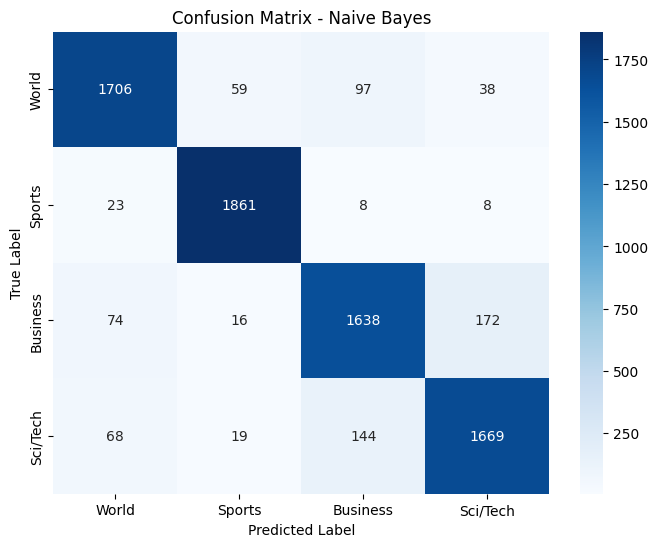


[INFO] Training Advanced Model (Support Vector Machine - LinearSVC)...
[INFO] SVM training completed in 26.55 seconds.
Accuracy: 92.45%

Classification Report : 
              precision    recall  f1-score   support

   World (1)       0.94      0.91      0.92      1900
  Sports (2)       0.96      0.99      0.97      1900
Business (3)       0.90      0.89      0.89      1900
Sci/Tech (4)       0.90      0.91      0.91      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600



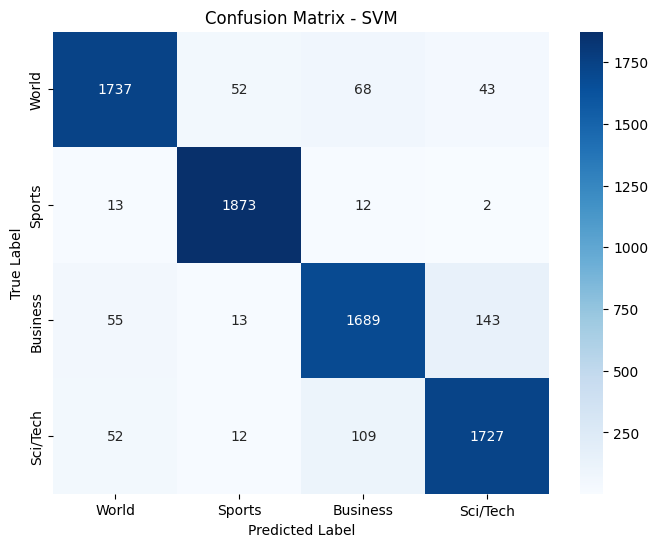


[INFO] Saved trained SVM pipeline to 'ag_news_svm_model.pkl' successfully


In [ ]:
if __name__ == "__main__":
  main()